# Experiment 2 — exploring the Norman perturbations

## In short
Before modelling anything, this notebook looks at the data and lays out what we will test.
**Part A** describes the data: which perturbations are strong, which look alike, how often each
gene appears in pairs, how the cells are split, and how grading against half vs all of the cells
changes a score. **Part B** asks how "additive" the real pairs
are. **Part C** has one section per research question. Each says, in plain words, what we are
asking, which split of the data it uses, which models we compare, which metrics we report, and
shows the slice of the data that matters for it.

Design documents: [`PLAN.md`](PLAN.md) (goals, models), [`SPLITS.md`](SPLITS.md) (splits).

| | question | split |
|---|---|---|
| Q1 | Can frozen STACK compose two perturbations at all? | S-all |
| Q2 | Which behaviour: replacement, preservation, additive, or interaction? | S-all |
| Q3 | Does the prompt–query order matter? | S-all |
| Q4 | Does fine-tuning help on held-out combinations (seen vs unseen genes)? | S-gene |
| Q5 | Does an order-consistency objective help? | S-gene (+ S-order) |
| Q6 | Additive vs non-additive pairs: is the interaction recovered? | inside every split |
| ref | Comparison with the team and Study 4 | S-shared |

## Technical details
- Data: `data/raw/norman/NormanWeissman2019_filtered.h5ad` (see `data/README.md`); STACK-vocabulary
  genes detected in ≥3 cells; `log1p(counts / ncounts · 1e4)`; effect δ = condition mean − control mean.
- Splits read: `splits/norman2019_conditions.csv`, `splits/norman2019_val_conditions.csv`,
  `splits/norman2019_halves.csv.gz`. S-all and S-gene are **previewed in memory only**.
- **Gene panel: `hvg2000`**, scanpy's top 2,000 highly variable genes
  (`sc.pp.highly_variable_genes`, Seurat flavor). It is chosen from **training-condition and control
  cells only** (no held-out double), and it is the same panel as the `hvg2000` rows in the scored
  results. It is loaded from `data/processed/compositional/s_shared_halves.npz`. Set `PANEL =
  "stack_genes"` in the setup cell to use all 11,789 STACK genes instead. STACK has no Norman-specific
  HVG list (its vocabulary is the union of the top-1,000 variable genes of its *training* datasets).
- **Perturbation strength** (A2): the number of DE genes vs control (Wilcoxon, BH-adjusted p < 0.05),
  as in Miller et al. and our proposal (~100 per perturbation in Norman), and the E-distance to
  control in PCA space (scPerturb, Peidli et al. 2024). ‖δ‖ is shown as a simple third view.
- "Top genes" for a pair (Parts B, C) = the panel genes with the largest |δ| (a quick proxy; the
  scored runs use the shared Wilcoxon / t-test DE).
- ⚠️ Parts B and C use all cells of every double, including held-out ones. This is for
  **looking only**, never for choosing settings. The non-additive flag (Q6) uses only the
  duplicate half, as specified in SPLITS.md.

In [1]:
from collections import Counter
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
import scanpy as sc
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA

from stack_robustness.data import log_normalize
from stack_robustness.de import rank_genes
from stack_robustness.evaluation import EvalContext
from stack_robustness.genes import load_stack_genes
from stack_compositional.report import STUDY4_NON_ADDITIVE

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "splits").is_dir())  # stack-robustness/
RAW = ROOT / "data/raw/norman/NormanWeissman2019_filtered.h5ad"
VOCAB = ROOT / "data/raw/stack_vocab/basecount_1000per_15000max.pkl"
CONTROL = "control"
PANEL = "hvg2000"   # or "stack_genes" for all 11,789 STACK genes
CONTEXT = ROOT / "data/processed/compositional/s_shared_halves.npz"   # written by scripts/build_contexts.py
pd.set_option("display.max_rows", 300)
plt.rcParams["figure.dpi"] = 110
ROOT

PosixPath('/Users/reetmishra/Documents/Github/cs182-finalproject/stack-robustness')

In [2]:
# Load cells (STACK genes, log-normalized). About a minute and a few GB of RAM.
backed = ad.read_h5ad(RAW, backed="r")
obs = backed.obs[["perturbation", "ncounts", "gemgroup"]].copy()
obs["condition"] = obs["perturbation"].astype(str).str.replace("_", "+", regex=False)
obs["kind"] = np.where(obs["condition"] == CONTROL, "control",
                       np.where(obs["condition"].str.contains("+", regex=False), "double", "single"))
in_vocab = backed.var_names.isin(set(load_stack_genes(VOCAB)))
X = sparse.csc_matrix(backed.X[:, in_vocab])          # stored column-major: reads only these genes
genes = backed.var_names[in_vocab]
backed.file.close()
detected = np.diff(X.indptr) >= 3
X = log_normalize(X[:, detected].tocsr(), obs["ncounts"].to_numpy())
genes = list(genes[detected])
halves = pd.read_csv(ROOT / "splits/norman2019_halves.csv.gz", index_col=0)["half"].reindex(obs.index)

def pseudobulk(mask):
    labels = obs["condition"].to_numpy()[mask]
    codes, groups = pd.factorize(labels, sort=True)
    ind = sparse.csr_matrix((1.0 / np.bincount(codes)[codes], (codes, np.arange(len(codes)))))
    return pd.DataFrame(np.asarray((ind @ X[mask]).todense()), index=groups, columns=genes)

counts = obs["condition"].value_counts()
if PANEL == "stack_genes":
    PANEL_GENES, panel_source = genes, "all STACK genes"
elif CONTEXT.exists():
    PANEL_GENES, panel_source = EvalContext.load(CONTEXT).panels[PANEL], str(CONTEXT.relative_to(ROOT))
else:  # same recipe as scripts/norman_baselines.py: training conditions + control cells of the shared split
    shared_split = pd.read_csv(ROOT / "splits/norman2019_conditions.csv")
    fit_cells = obs["condition"].isin(set(shared_split.loc[shared_split["split"] == "train", "condition"]) | {CONTROL})
    tmp = ad.AnnData(X=X[fit_cells.to_numpy()], var=pd.DataFrame(index=genes))
    hv = sc.pp.highly_variable_genes(tmp, n_top_genes=2000, inplace=False)
    PANEL_GENES, panel_source = list(tmp.var_names[hv["highly_variable"].to_numpy()]), "computed here (scanpy HVG)"
gene_pos = pd.Series(np.arange(len(genes)), index=genes)
panel_idx = gene_pos[PANEL_GENES].to_numpy()
print(f"panel {PANEL}: {len(PANEL_GENES)} genes, from {panel_source}")

profiles_all = pseudobulk(np.ones(len(obs), bool))               # all genes (used only in A6)
profiles = profiles_all[PANEL_GENES]
effects = profiles - profiles.loc[CONTROL]                       # δ on the panel, all cells
dup_profiles = pseudobulk((halves == "second").to_numpy())[PANEL_GENES]
dup_effects = dup_profiles - profiles.loc[CONTROL]               # δ from the duplicate half (doubles)

singles = sorted(c for c in counts.index if c != CONTROL and "+" not in c)
doubles = sorted(c for c in counts.index if "+" in c)
print(X.shape, "cells x genes;", len(singles), "singles,", len(doubles), "doubles")

panel hvg2000: 2000 genes, from data/processed/compositional/s_shared_halves.npz


(111445, 11789) cells x genes; 105 singles, 131 doubles


# Part A — the data

## A1. Cells and conditions
**In short:** each cell is either a control (nothing switched on), a single (one gene switched
on) or a double (two genes). More cells means a less noisy average.

,cells,conditions
kind,,
control,11855,1
double,41759,131
single,57831,105


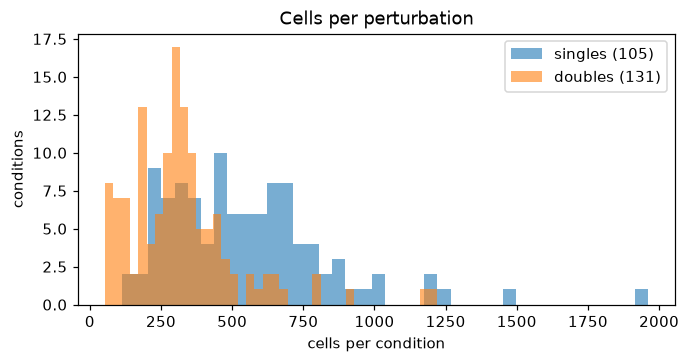

smallest doubles: {'JUN+CEBPA': 54, 'C3orf72+FOXL2': 59, 'JUN+CEBPB': 59, 'CBL+UBASH3A': 64, 'CEBPB+CEBPA': 64}


In [3]:
display(obs.groupby("kind", observed=True)["condition"].agg(cells="size", conditions="nunique"))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(counts[singles], bins=40, alpha=0.6, label=f"singles ({len(singles)})")
ax.hist(counts[doubles], bins=40, alpha=0.6, label=f"doubles ({len(doubles)})")
ax.set(xlabel="cells per condition", ylabel="conditions", title="Cells per perturbation"); ax.legend()
plt.show()
print("smallest doubles:", counts[doubles].nsmallest(5).to_dict())

## A2. Which perturbations have the strongest effect?
**In short:** some perturbations barely change the cell, others change hundreds of genes.
Strong ones are easier to predict well and dominate averaged scores. We measure strength the way
the field does:
- **DE genes:** how many genes change significantly compared with control cells. This is the
  measure in Miller et al. and our proposal; Norman averages ~100 per perturbation.
- **E-distance:** how far the perturbed cells sit from control cells as a whole cloud, not just on
  average. scPerturb, the source of our data file, uses it to rank perturbation strength.
- **‖δ‖:** the length of the average change, a simple third view.

**Technical:**
- DE genes: Wilcoxon vs control (`stack_robustness.de.rank_genes`, `method="wilcoxon"`) on the
  HVG panel; BH-adjusted p < 0.05.
- E-distance (Peidli et al. 2024): $2\,\mathbb{E}\lVert x-y\rVert - \mathbb{E}\lVert x-x'\rVert -
  \mathbb{E}\lVert y-y'\rVert$, Euclidean in 50 PCs of the HVG panel. Up to 300 cells per condition
  and 2,000 control cells (seed 0).
- Both grow with cell number (more cells give more power and less noise), so compare conditions
  with similar counts with care.
- ‖δ‖ = L2 norm of the mean change on the panel.
- DE takes a few minutes.

/Users/reetmishra/Documents/Github/cs182-finalproject/envs/.venv/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:609: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/Users/reetmishra/Documents/Github/cs182-finalproject/envs/.venv/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:612: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "pvals"] = pvals[global_indices]
/Users/reetmishra/Documents/Github/cs182-finalproject/envs/.

/Users/reetmishra/Documents/Github/cs182-finalproject/envs/.venv/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:607: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]


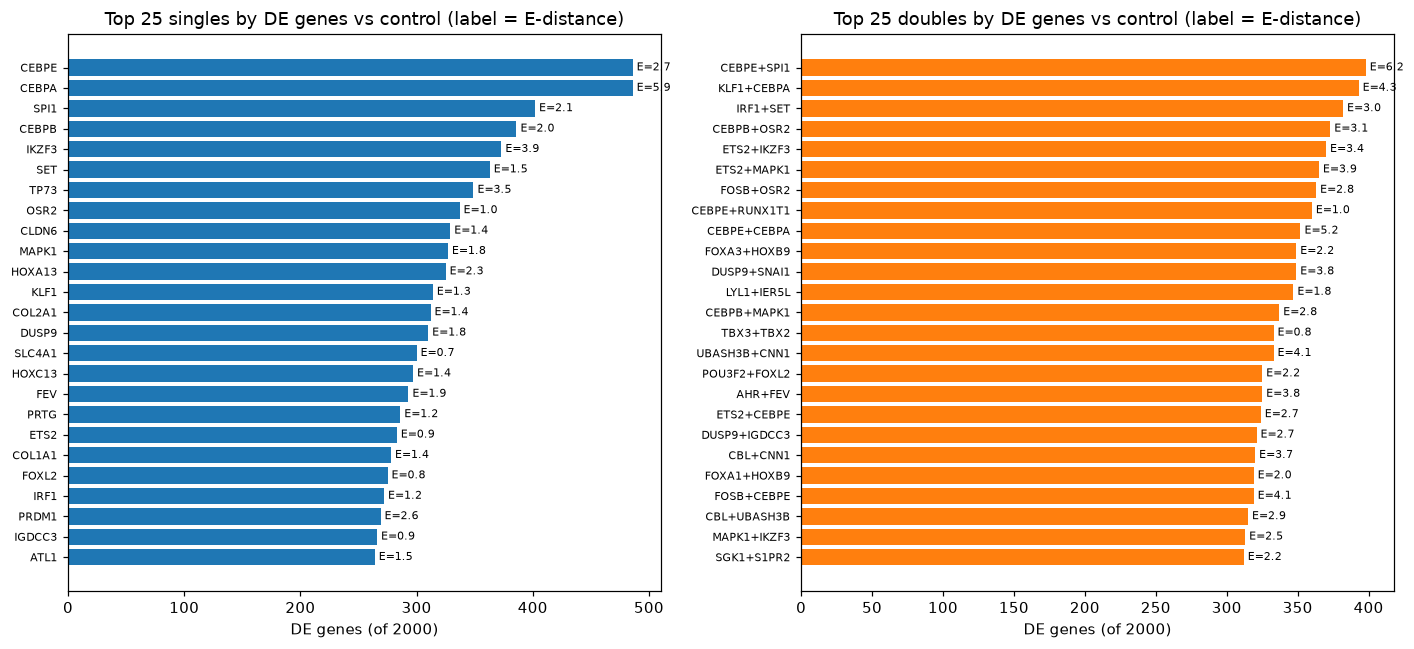

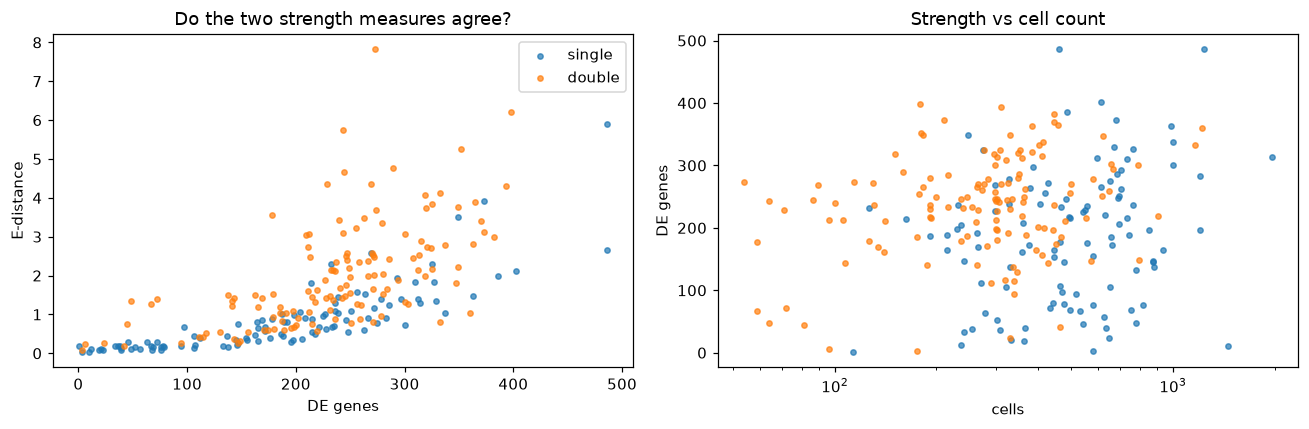

Spearman(DE genes, E-distance) = 0.779
median DE genes — singles: 189.0 | doubles: 243.0


,DE genes,E-distance,‖δ‖,cells,kind
CEBPA,486,5.89,8.49,460,single
CEBPE,486,2.66,5.04,1233,single
SPI1,402,2.12,4.55,613,single
CEBPE+SPI1,398,6.20,8.29,179,double
KLF1+CEBPA,393,4.31,6.80,311,double
CEBPB,386,1.98,4.45,488,single
IRF1+SET,382,2.99,5.16,444,double
CEBPB+OSR2,373,3.13,5.78,211,double
IKZF3,373,3.93,5.95,681,single
ETS2+IKZF3,370,3.40,5.82,445,double


In [4]:
rng = np.random.default_rng(0)
conds = [c for c in counts.index if c != CONTROL]

# DE genes vs control (Wilcoxon) on the panel
adata_panel = ad.AnnData(X=X[:, panel_idx], obs=obs[["condition"]], var=pd.DataFrame(index=PANEL_GENES))
de_ctrl_all = rank_genes(adata_panel, "condition", reference=CONTROL, method="wilcoxon")
n_de = pd.Series({c: int((de_ctrl_all[c]["pval_adj"] < 0.05).sum()) for c in conds})

# E-distance to control in PCA space (scPerturb)
sub = {c: rng.choice(np.flatnonzero((obs["condition"] == c).to_numpy()), size=min(counts[c], 2000 if c == CONTROL else 300), replace=False)
       for c in counts.index}
rows_sub = np.concatenate(list(sub.values()))
pca = PCA(n_components=50, random_state=0).fit(X[rows_sub][:, panel_idx].toarray())
emb = {c: pca.transform(X[r][:, panel_idx].toarray()) for c, r in sub.items()}
ctrl_self = cdist(emb[CONTROL], emb[CONTROL]).mean()
e_dist = pd.Series({c: 2 * cdist(emb[c], emb[CONTROL]).mean() - cdist(emb[c], emb[c]).mean() - ctrl_self for c in conds})

strength = pd.DataFrame({"DE genes": n_de, "E-distance": e_dist,
                         "‖δ‖": np.linalg.norm(effects.loc[conds], axis=1), "cells": counts[conds]}, index=conds)
strength["kind"] = np.where(strength.index.str.contains("+", regex=False), "double", "single")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, kind in zip(axes, ["single", "double"]):
    top = strength[strength["kind"] == kind].nlargest(25, "DE genes")[::-1]
    ax.barh(top.index, top["DE genes"], color="C0" if kind == "single" else "C1")
    for y, (v, e) in enumerate(zip(top["DE genes"], top["E-distance"])):
        ax.text(v, y, f" E={e:.1f}", va="center", fontsize=7)
    ax.set(title=f"Top 25 {kind}s by DE genes vs control (label = E-distance)", xlabel=f"DE genes (of {len(PANEL_GENES)})")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (x, y) in zip(axes, [("DE genes", "E-distance"), ("cells", "DE genes")]):
    for kind, color in [("single", "C0"), ("double", "C1")]:
        g = strength[strength["kind"] == kind]
        ax.scatter(g[x], g[y], s=12, alpha=0.7, c=color, label=kind)
    ax.set(xlabel=x, ylabel=y, xscale="log" if x == "cells" else "linear")
axes[0].set_title("Do the two strength measures agree?"); axes[1].set_title("Strength vs cell count")
axes[0].legend(); plt.tight_layout(); plt.show()
print("Spearman(DE genes, E-distance) =", round(strength["DE genes"].corr(strength["E-distance"], method="spearman"), 3))
print("median DE genes — singles:", strength.query("kind == 'single'")["DE genes"].median(),
      "| doubles:", strength.query("kind == 'double'")["DE genes"].median())
strength.sort_values("DE genes", ascending=False).head(10).round(2)

## A3. Which perturbations are similar to each other?
**In short:** perturbations that act on the same biological program shift the cells in the same
direction. Norman et al. found clear groups (e.g. erythroid/megakaryocyte genes, granulocyte
genes, pro-growth genes). Similar effects are what a model could borrow from.

**Technical:** correlation of δ between all 236 perturbations on the HVG panel; average-linkage
clustering on correlation distance; PCA of the same matrix (perturbations × HVGs).

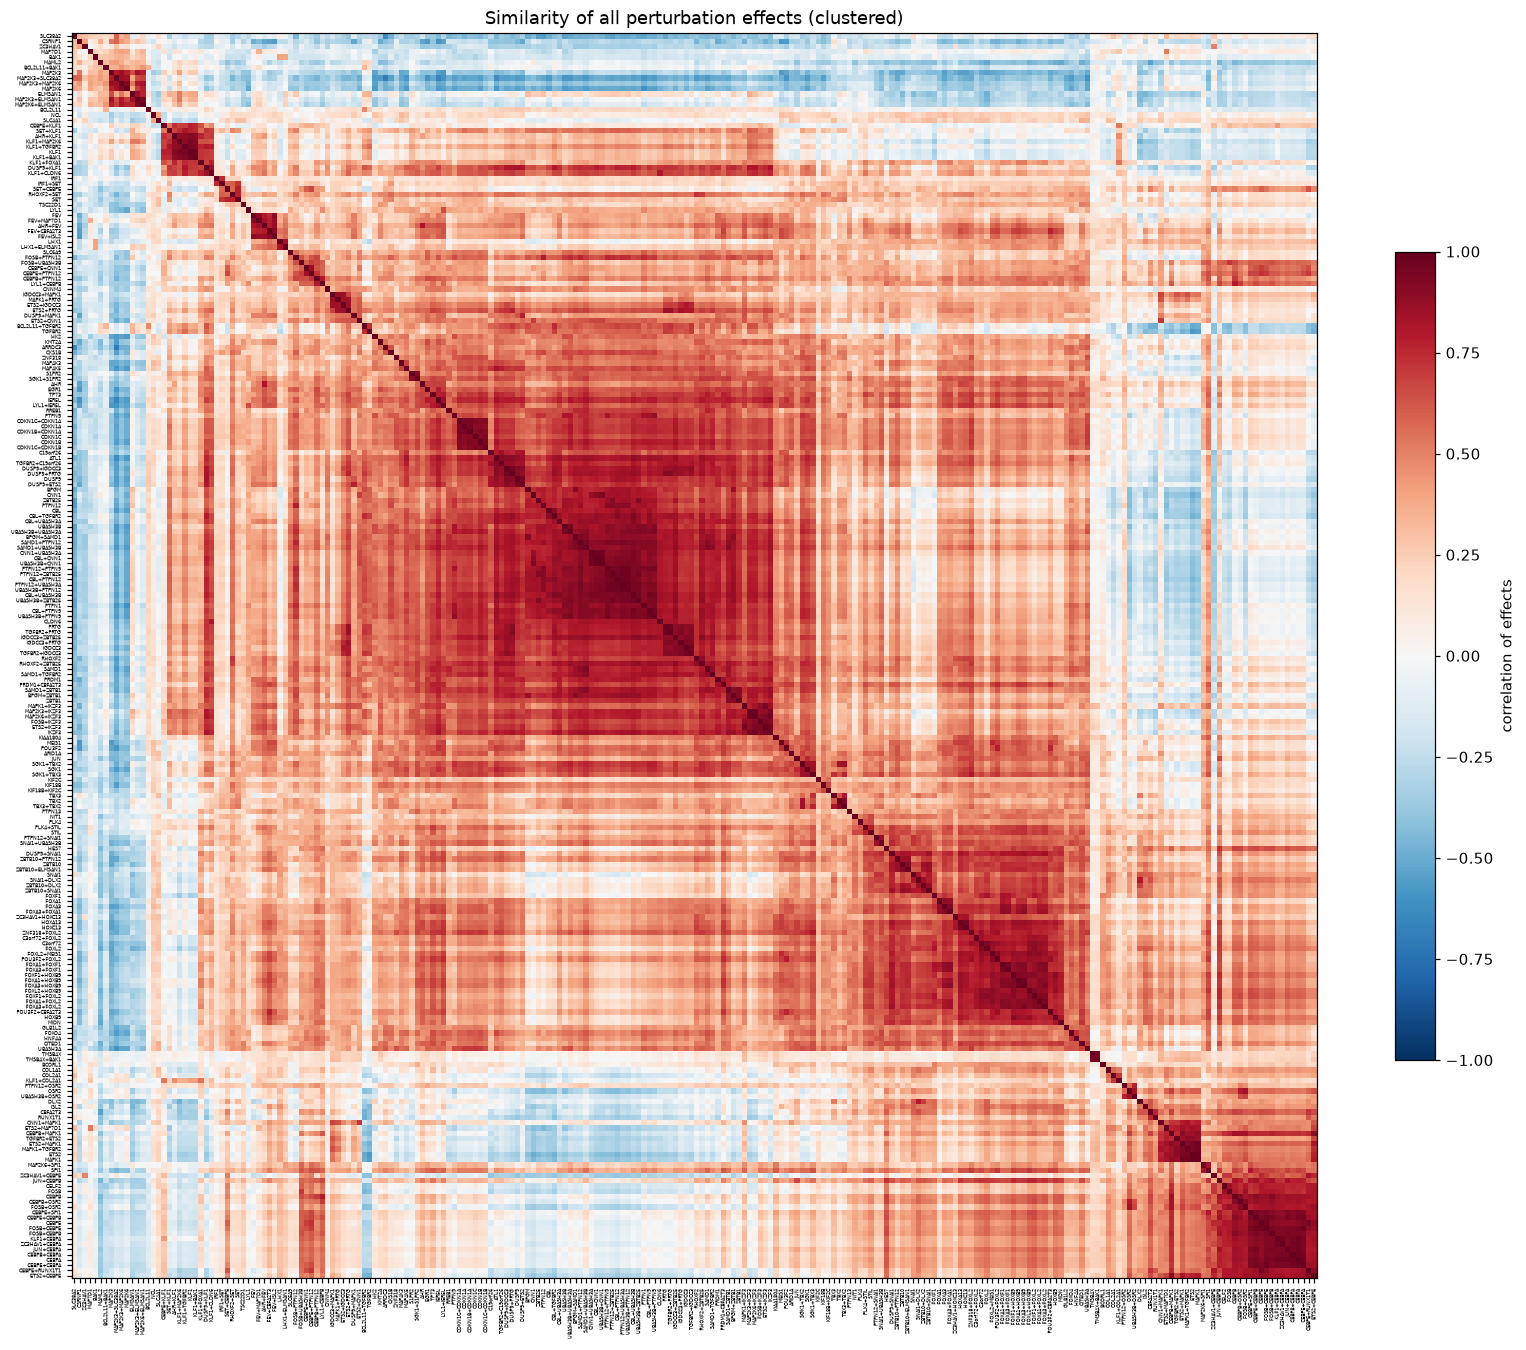

In [5]:
E = effects.drop(CONTROL)
corr = np.corrcoef(E.to_numpy())
order = leaves_list(linkage(E.to_numpy(), method="average", metric="correlation"))
names = E.index[order]

fig, ax = plt.subplots(figsize=(15, 15))
im = ax.imshow(corr[np.ix_(order, order)], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=90, fontsize=3.5)
ax.set_yticks(range(len(names)), names, fontsize=3.5)
fig.colorbar(im, ax=ax, shrink=0.5, label="correlation of effects")
ax.set_title("Similarity of all perturbation effects (clustered)")
plt.tight_layout(); plt.show()

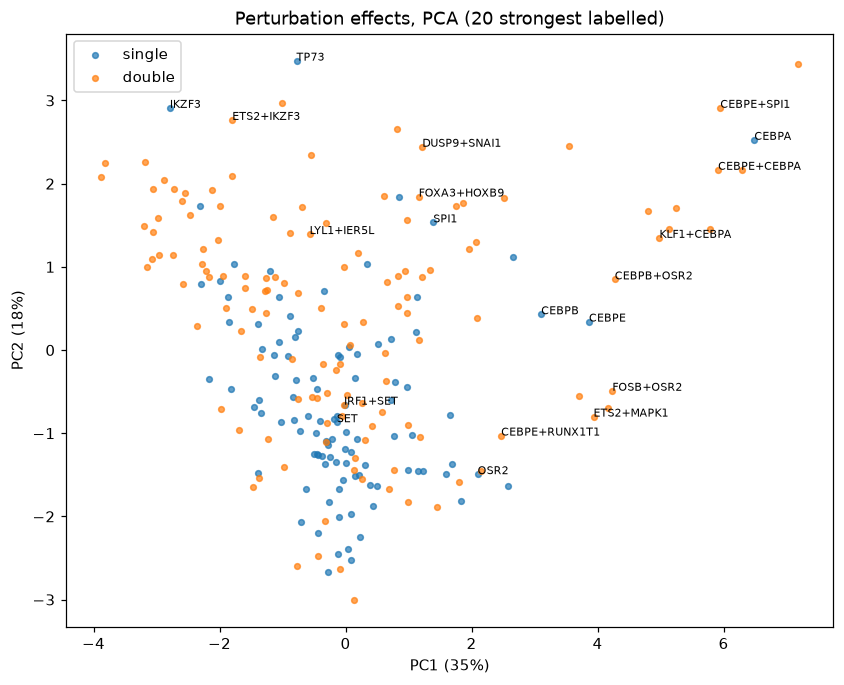

KLF1+BAK1       0.973
KLF1+TGFBR2     0.952
KLF1+MAP2K6     0.944
AHR+KLF1        0.917
SET+KLF1        0.773
CEBPE+KLF1      0.767
KLF1+FOXA1      0.722
DUSP9+KLF1      0.704
KLF1+CLDN6      0.683
MAP2K3+IKZF3    0.527
dtype: float64

In [6]:
Z = E.to_numpy() - E.to_numpy().mean(axis=0)
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
pcs = pd.DataFrame(U[:, :2] * S[:2], index=E.index, columns=["PC1", "PC2"])
explained = S[:2] ** 2 / (S ** 2).sum()

fig, ax = plt.subplots(figsize=(9, 7))
for kind, color in [("single", "C0"), ("double", "C1")]:
    sel = strength.loc[pcs.index, "kind"] == kind
    ax.scatter(pcs.loc[sel, "PC1"], pcs.loc[sel, "PC2"], s=14, alpha=0.7, c=color, label=kind)
for name in strength["DE genes"].nlargest(20).index:
    ax.annotate(name, pcs.loc[name], fontsize=7)
ax.set(xlabel=f"PC1 ({explained[0]:.0%})", ylabel=f"PC2 ({explained[1]:.0%})",
       title="Perturbation effects, PCA (20 strongest labelled)"); ax.legend()
plt.show()

def most_similar(cond, k=10):
    """The k perturbations whose effects correlate most with `cond`."""
    i = list(E.index).index(cond)
    return pd.Series(corr[i], index=E.index).drop(cond).nlargest(k).round(3)

most_similar("KLF1")

## A4. How often each gene appears in pairs
**In short:** a model can learn a lot about a gene from other pairs containing it. KLF1 is in 11
pairs, but 20 genes are in only one pair. This is why the fine-tuning question needs a split that
hides some genes completely (S-gene), not just random pairs.

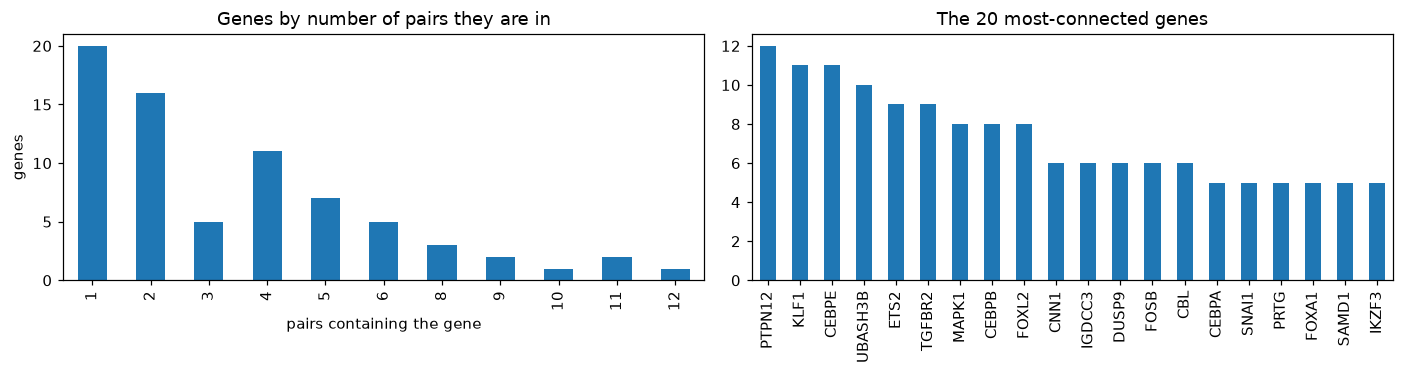

73 genes appear in doubles; all have a measured single: True


In [7]:
degree = Counter(g for d in doubles for g in d.split("+"))
degree = pd.Series(degree).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
degree.value_counts().sort_index().plot.bar(ax=axes[0], title="Genes by number of pairs they are in")
axes[0].set(xlabel="pairs containing the gene", ylabel="genes")
degree.head(20).plot.bar(ax=axes[1], title="The 20 most-connected genes")
plt.tight_layout(); plt.show()
print(len(degree), "genes appear in doubles; all have a measured single:", set(degree.index) <= set(singles))

## A5. Truth and duplicate halves
**In short:** every condition's cells were split at random into two halves. Models are graded
against the **first** half. The **second** half is the *technical duplicate*: if we "predict" the
first half using the second half of the real measurements, we see the best score possible given
measurement noise. A model scoring near the duplicate is about as good as a repeat experiment.

**Technical:** `splits/norman2019_halves.csv.gz` (team convention, Miller et al.). The interpolated
duplicate blends the duplicate with the mean baseline per gene (α = 1 − adjusted p).

In [8]:
half_table = pd.crosstab(obs["kind"], halves)
display(half_table)
print("first-half cells of the smallest doubles:",
      {d: int(((obs["condition"] == d) & (halves == "first")).sum()) for d in counts[doubles].nsmallest(4).index})

half,first,second
kind,,
control,5927,5928
double,20845,20914
single,28890,28941


first-half cells of the smallest doubles: {'JUN+CEBPA': 27, 'C3orf72+FOXL2': 29, 'JUN+CEBPB': 29, 'CBL+UBASH3A': 32}


## A6. Grading against half the cells vs all cells
**In short:** we grade every model two ways:
- against a random **half** of each held-out pair's cells (team convention; the other half is the
  repeat-experiment reference);
- against **all** of its cells.

Using all cells makes the "right answer" less noisy. Here we see how much that changes the score
of one fixed prediction, the additive baseline, on the 26 held-out pairs of the team split.
Small pairs should move the most.

**Technical:** Pearson of Δ from control and MSE, additive prediction vs the first-half mean and
vs the all-cells mean, on the HVG panel (`PANEL`). `EVALUATION.md` reports the same comparison on
the full STACK gene panel. The scored runs use `stack_compositional.contexts`
(`truth="halves"` / `"all"`), which also recompute the DE genes for each mode.

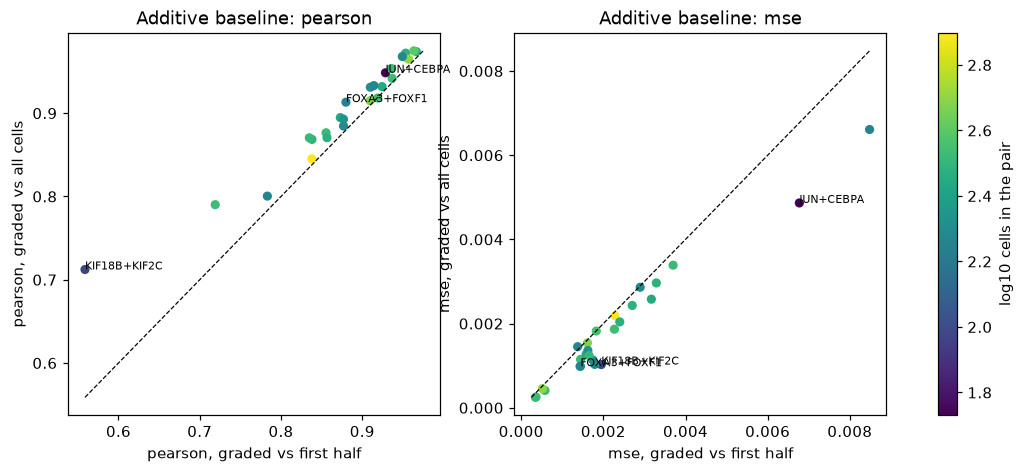

[hvg2000] median Pearson — halves: 0.91 | all cells: 0.917   (team summary, hvg2000, halves: 0.910; STACK panel in EVALUATION.md: 0.828 / 0.871)


,cells,first-half cells,pearson (halves),pearson (all cells),mse (halves),mse (all cells),Δ pearson (all − halves)
JUN+CEBPA,54.0,27.0,0.9285,0.9485,0.0068,0.0049,0.0200
KIF18B+KIF2C,96.0,48.0,0.5588,0.7123,0.0019,0.0010,0.1535
FOXA3+FOXF1,175.0,87.0,0.8799,0.9133,0.0014,0.0010,0.0334
ZBTB10+ELMSAN1,182.0,91.0,0.9143,0.9331,0.0014,0.0015,0.0188
DUSP9+SNAI1,183.0,91.0,0.7832,0.8004,0.0085,0.0066,0.0172
SAMD1+ZBTB1,191.0,95.0,0.9493,0.9681,0.0018,0.0010,0.0188
LYL1+CEBPB,192.0,96.0,0.8769,0.8846,0.0029,0.0029,0.0077
FOXF1+HOXB9,200.0,100.0,0.9099,0.9312,0.0017,0.0011,0.0213
POU3F2+CBFA2T3,216.0,108.0,0.8769,0.8929,0.0016,0.0014,0.0160
FOXA1+FOXF1,272.0,136.0,0.8730,0.8947,0.0016,0.0013,0.0218


In [9]:
first_profiles = pseudobulk((halves == "first").to_numpy())[PANEL_GENES]
shared_split = pd.read_csv(ROOT / "splits/norman2019_conditions.csv")
shared_test = shared_split.loc[shared_split["split"].eq("test"), "condition"].tolist()
ctrl_profile = profiles.loc[CONTROL]

def score(pred, truth):
    return {"pearson": np.corrcoef(pred - ctrl_profile, truth - ctrl_profile)[0, 1],
            "mse": float(((pred - truth) ** 2).mean())}

rows = {}
for d in shared_test:
    a, b = d.split("+")
    pred = ctrl_profile + effects.loc[a] + effects.loc[b]
    h, f = score(pred, first_profiles.loc[d]), score(pred, profiles.loc[d])
    rows[d] = {"cells": counts[d], "first-half cells": int(((obs["condition"] == d) & (halves == "first")).sum()),
               "pearson (halves)": h["pearson"], "pearson (all cells)": f["pearson"],
               "mse (halves)": h["mse"], "mse (all cells)": f["mse"]}
modes = pd.DataFrame(rows).T
modes["Δ pearson (all − halves)"] = modes["pearson (all cells)"] - modes["pearson (halves)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, m in zip(axes, ["pearson", "mse"]):
    sc_ = ax.scatter(modes[f"{m} (halves)"], modes[f"{m} (all cells)"], c=np.log10(modes["cells"].astype(float)), cmap="viridis", s=25)
    lo, hi = modes[[f"{m} (halves)", f"{m} (all cells)"]].to_numpy().min(), modes[[f"{m} (halves)", f"{m} (all cells)"]].to_numpy().max()
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
    for d in modes["cells"].astype(float).nsmallest(3).index:
        ax.annotate(d, (modes.loc[d, f"{m} (halves)"], modes.loc[d, f"{m} (all cells)"]), fontsize=7)
    ax.set(xlabel=f"{m}, graded vs first half", ylabel=f"{m}, graded vs all cells", title=f"Additive baseline: {m}")
fig.colorbar(sc_, ax=axes, label="log10 cells in the pair")
plt.show()
print(f"[{PANEL}] median Pearson — halves:", round(modes["pearson (halves)"].median(), 3),
      "| all cells:", round(modes["pearson (all cells)"].median(), 3),
      "  (team summary, hvg2000, halves: 0.910; STACK panel in EVALUATION.md: 0.828 / 0.871)")
modes.sort_values("cells").round(4)

# Part B — how additive are the real pairs?

**In short:** for each pair we compare the measured double effect with the sum of its two single
effects. If they match, the pair is *additive*, and the simple "add them" baseline will be hard to
beat. Points above the diagonal are stronger than the sum (synergy), below are weaker (buffering).

**Technical** (same genes and fits as the scoring and the reference methods; nothing new):
- **Genes:** the HVG panel; and, per pair, its **top-100 DE genes**: t-test with overestimated
  variance of the pair's first half vs all other perturbed first-half cells, top by adjusted p with
  ties broken by |t|. That is exactly the gene set of the scoring's `_top` metrics
  (`stack_robustness.scoring._top_mask`).
- **Truth:** first-half mean of the double. Singles use all their cells.
- **Weights c₁, c₂:** the reference's *specific epistasis* fit, μ_AB = μ₀ + c₁δ_A + c₂δ_B + ε, with
  per-pair c's and one shared gene offset ε, as one joint least-squares fit over all 131 doubles on
  the panel (`stack_compositional.additivity.specific_epistasis_fit`). Same idea as Norman et al.'s
  c_A/c_B. (1, 1) = additive; (1, 0) or (0, 1) = one gene dominates; both below 1 = buffering;
  above 1 = synergy.
- **Ruler score** (Q6): where the plain sum A + B lands between "as good as a redo" (0) and "as bad as
  nothing" (1), on wMSE.

In [10]:
from stack_compositional.additivity import additivity_groups, calibrated, specific_epistasis_fit
from stack_robustness.metrics import deg_weights, wmse
from stack_robustness.scoring import _top_mask

first = (halves == "first").to_numpy()
second = (halves == "second").to_numpy()
is_ctrl = (obs["condition"] == CONTROL).to_numpy()
ctrl_all = profiles_all.loc[CONTROL]
single_eff_all = profiles_all.loc[singles] - ctrl_all
truth_all = pseudobulk(first).loc[doubles]
redo_all = pseudobulk(second).loc[doubles]

# DE exactly as in the shared scoring: t-test (overestimated variance) of each condition's first half
# vs all other perturbed first-half cells. Gives the wMSE weights and the top-100 genes. ~1-2 minutes.
sel = first & ~is_ctrl
de_rest_first = rank_genes(ad.AnnData(X=X[sel], obs=obs.loc[sel, ["condition"]], var=pd.DataFrame(index=genes)),
                           "condition", reference="rest")

def top_de(pair, panel_genes, k=100):
    de = de_rest_first[pair].reindex(panel_genes)
    return list(np.asarray(panel_genes)[_top_mask(de["pval_adj"].to_numpy(), de["score"].to_numpy(), k)])

def ruler_table(panel_genes):
    ctrl = ctrl_all[panel_genes]
    eff = single_eff_all[panel_genes]
    truth, redo = truth_all[panel_genes], redo_all[panel_genes]
    coefs, _, stretched = specific_epistasis_fit(ctrl, eff, truth)
    rows = {}
    for d in doubles:
        a, b = d.split("+")
        dA, dB, dAB = eff.loc[a], eff.loc[b], truth.loc[d] - ctrl
        top = top_de(d, panel_genes)
        w = deg_weights(de_rest_first[d]["score"].reindex(panel_genes).to_numpy())
        t = truth.loc[d].to_numpy()
        err = lambda pred: wmse(np.asarray(pred, dtype=float), t, w)
        e_sum, e_redo, e_none, e_str = err(ctrl + dA + dB), err(redo.loc[d]), err(ctrl), err(stretched.loc[d])
        rows[d] = {"score: plain sum": calibrated(e_sum, e_redo, e_none),
                   "score: stretched sum": calibrated(e_str, e_redo, e_none),
                   "c1 (first gene)": coefs.loc[d, "c1"], "c2 (second gene)": coefs.loc[d, "c2"],
                   "|AB| top-100 DE": np.linalg.norm(dAB[top]), "|A+B| top-100 DE": np.linalg.norm((dA + dB)[top]),
                   "pearson(AB, A+B) panel": np.corrcoef(dAB, dA + dB)[0, 1],
                   "pearson(AB, A+B) top-100 DE": np.corrcoef(dAB[top], (dA + dB)[top])[0, 1],
                   "wMSE plain sum": e_sum, "wMSE redo": e_redo, "wMSE nothing": e_none,
                   "cells": counts[d], "Study 4 list": d in STUDY4_NON_ADDITIVE}
    return pd.DataFrame(rows).T.infer_objects()

ruler = {PANEL: ruler_table(PANEL_GENES)}
if PANEL != "stack_genes":
    ruler["stack_genes"] = ruler_table(genes)
additivity = ruler[PANEL]
# Agreed rule (SPLITS.md): top 25% of the plain-sum score = non-additive; of those, the ones whose
# stretched sum is still above the same cut = interaction, the rest = buffering/synergy.
groups, CUT = additivity_groups(additivity["score: plain sum"], additivity["score: stretched sum"])
additivity["group"] = groups
for name, r in ruler.items():
    print(f"[{name}] pairs on the ruler: {r['score: plain sum'].notna().sum()} of {len(r)} "
          f"(dropped where the redo is not better than control: {sorted(r.index[r['score: plain sum'].isna()])})")
print(f"groups [{PANEL}], cut = {CUT:.3f}:", groups.value_counts().to_dict())
saved = ROOT / "splits/compositional/additivity_groups.csv"
if saved.exists() and PANEL == "hvg2000":
    same = pd.read_csv(saved, index_col="pair")["group"].reindex(groups.index).eq(groups).all()
    print("matches splits/compositional/additivity_groups.csv:", bool(same))

/Users/reetmishra/Documents/Github/cs182-finalproject/envs/.venv/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:609: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/Users/reetmishra/Documents/Github/cs182-finalproject/envs/.venv/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:612: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "pvals"] = pvals[global_indices]
/Users/reetmishra/Documents/Github/cs182-finalproject/envs/.

[hvg2000] pairs on the ruler: 131 of 131 (dropped where the redo is not better than control: [])
[stack_genes] pairs on the ruler: 130 of 131 (dropped where the redo is not better than control: ['KIF18B+KIF2C'])
groups [hvg2000], cut = 0.117: {'additive': 98, 'buffering/synergy': 23, 'interaction': 10}
matches splits/compositional/additivity_groups.csv: True


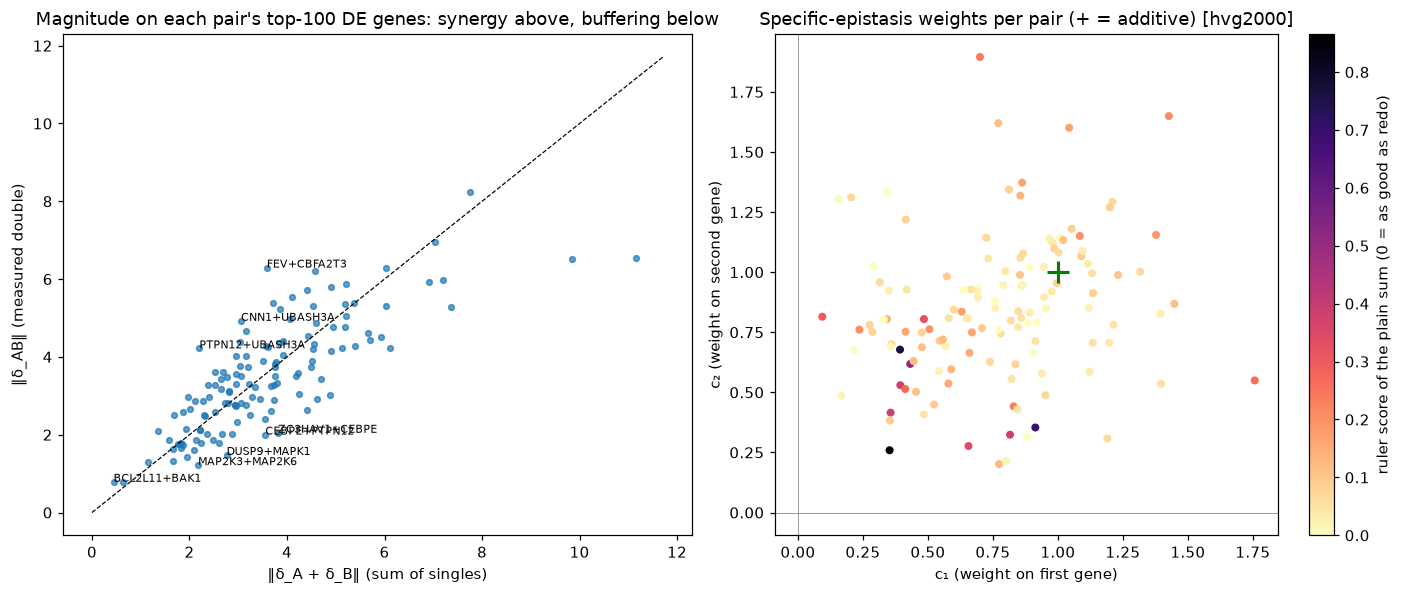

,score: plain sum,score: stretched sum,c1 (first gene),c2 (second gene),|AB| top-100 DE,|A+B| top-100 DE,"pearson(AB, A+B) panel","pearson(AB, A+B) top-100 DE",wMSE plain sum,wMSE redo,wMSE nothing,cells,Study 4 list,group
DUSP9+MAPK1,0.865,0.284,0.353,0.259,1.479,2.761,0.801,0.837,0.019,0.002,0.022,290,False,interaction
MAP2K3+MAP2K6,0.768,0.000,0.393,0.678,1.218,2.177,0.910,0.961,0.010,0.002,0.013,571,False,buffering/synergy
ZC3HAV1+CEBPE,0.690,0.095,0.913,0.354,2.050,3.816,0.874,0.933,0.054,0.002,0.078,410,False,buffering/synergy
CEBPE+CEBPA,0.512,0.012,0.432,0.618,6.555,11.153,0.971,0.981,0.204,0.007,0.392,180,False,buffering/synergy
IGDCC3+PRTG,0.387,0.000,0.816,0.324,3.032,4.877,0.932,0.958,0.059,0.008,0.140,140,False,buffering/synergy
MAP2K6+SPI1,0.381,0.185,0.356,0.416,1.786,2.600,0.838,0.905,0.021,0.002,0.052,302,True,interaction
CEBPE+PTPN12,0.377,0.156,0.394,0.530,2.003,3.557,0.885,0.915,0.054,0.001,0.140,415,False,interaction
SET+CEBPE,0.344,0.236,0.656,0.277,2.908,4.616,0.843,0.905,0.071,0.001,0.203,658,False,interaction
CEBPE+RUNX1T1,0.325,0.075,0.485,0.805,2.627,4.414,0.963,0.979,0.049,0.001,0.150,1219,False,buffering/synergy
CEBPB+CEBPA,0.301,0.000,0.094,0.815,6.508,9.853,0.931,0.976,0.109,0.016,0.323,64,False,buffering/synergy


In [11]:
a = additivity
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
ax = axes[0]
ax.scatter(a["|A+B| top-100 DE"], a["|AB| top-100 DE"], s=14, alpha=0.7)
lim = a[["|AB| top-100 DE", "|A+B| top-100 DE"]].to_numpy().max() * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=0.8)
ratio = a["|AB| top-100 DE"] / a["|A+B| top-100 DE"]
for d in ratio.nlargest(4).index.union(ratio.nsmallest(4).index):
    ax.annotate(d, (a.loc[d, "|A+B| top-100 DE"], a.loc[d, "|AB| top-100 DE"]), fontsize=7)
ax.set(xlabel="‖δ_A + δ_B‖ (sum of singles)", ylabel="‖δ_AB‖ (measured double)",
       title="Magnitude on each pair's top-100 DE genes: synergy above, buffering below")
ax = axes[1]
sc_ = ax.scatter(a["c1 (first gene)"], a["c2 (second gene)"], c=a["score: plain sum"].clip(upper=1.5), cmap="magma_r", s=18)
ax.plot([1], [1], "g+", ms=14, mew=2)
ax.axhline(0, c="grey", lw=0.5); ax.axvline(0, c="grey", lw=0.5)
fig.colorbar(sc_, ax=ax, label="ruler score of the plain sum (0 = as good as redo)")
ax.set(xlabel="c₁ (weight on first gene)", ylabel="c₂ (weight on second gene)",
       title=f"Specific-epistasis weights per pair (+ = additive) [{PANEL}]")
plt.tight_layout(); plt.show()
a.sort_values("score: plain sum", ascending=False).head(15).round(3)

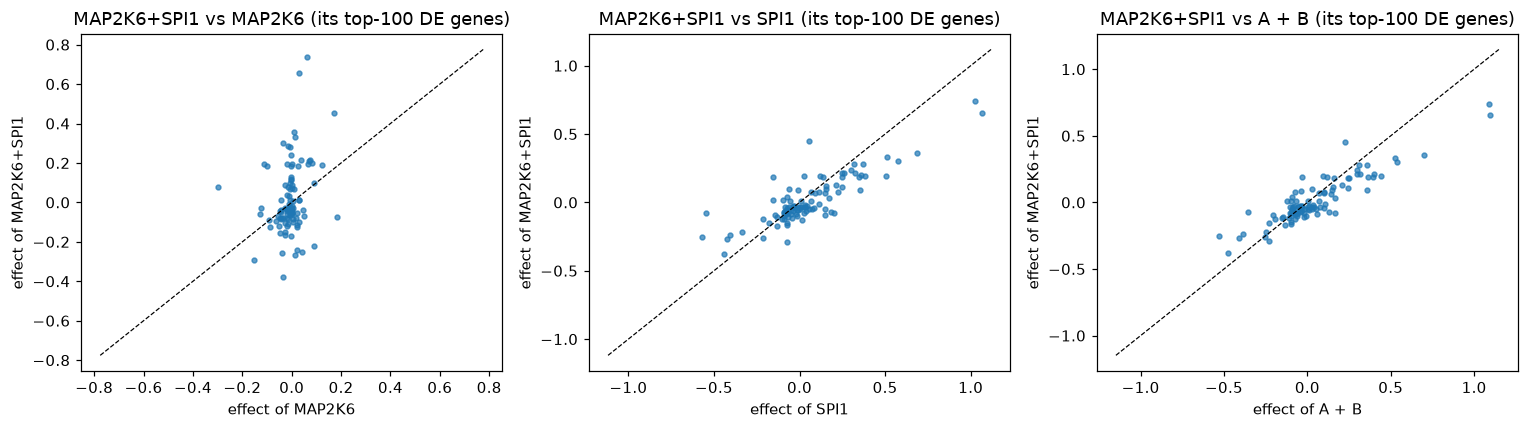

c1 = 0.36, c2 = 0.42, ruler score plain sum = 0.38


In [12]:
PAIR = "MAP2K6+SPI1"   # change to any double
a_, b_ = PAIR.split("+")
dA, dB = single_eff_all.loc[a_, PANEL_GENES], single_eff_all.loc[b_, PANEL_GENES]
dAB = truth_all.loc[PAIR, PANEL_GENES] - ctrl_all[PANEL_GENES]
top = top_de(PAIR, PANEL_GENES)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (x, label) in zip(axes, [(dA, a_), (dB, b_), (dA + dB, "A + B")]):
    ax.scatter(x[top], dAB[top], s=10, alpha=0.7)
    lim = max(np.abs(x[top]).max(), np.abs(dAB[top]).max()) * 1.05
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
    ax.set(xlabel=f"effect of {label}", ylabel=f"effect of {PAIR}", title=f"{PAIR} vs {label} (its top-100 DE genes)")
plt.tight_layout(); plt.show()
print(f"c1 = {additivity.loc[PAIR, 'c1 (first gene)']:.2f}, c2 = {additivity.loc[PAIR, 'c2 (second gene)']:.2f}, "
      f"ruler score plain sum = {additivity.loc[PAIR, 'score: plain sum']:.2f}")

# Part C — the research questions

Each section: **In short** (plain words), **Split**, **Models tested**, **Metrics**, then a look
at the data that matters for that question. Metric reminders:
- **wMSE** (primary): squared error weighted toward the genes the perturbation changes most.
  Lower is better.
- **Pearson Δ**: correlation of predicted and true change from control. 1 is perfect.
- **DE AUPRC**: does the prediction rank the truly changed genes first? Higher is better.
- **Direction agreement**: share of truly changed genes moved in the right direction.
- Every metric is read against the negative controls (control, mean) and the positive controls
  (technical and interpolated duplicate).

## Q1 — Can frozen STACK compose two perturbations at all?

**In short:** we show STACK cells with gene A on (prompt) and cells with gene B on (query), with no
extra training, and ask for cells with both. Does its prediction beat simply adding the two
single effects, or even just returning B's effect unchanged?

**Split — S-all:** all 131 doubles, because frozen STACK is not trained on anything, so no pair
can leak. The only fitted thing, the weights of `weighted`, is cross-fitted over 5 folds.

**Models tested:**
| model | what it tells us |
|---|---|
| `stack_frozen` (A→B and B→A) | the question itself |
| `additive` δ_A + δ_B | the bar to beat; strong on Norman |
| `weighted` w_A δ̂_A + w_B δ̂_B | STACK's own published recipe for combinations |
| `query_only` δ_B, `prompt_only` δ_A | doing nothing / copying the prompt |
| control, mean | negative controls (uninformative) |
| technical, interpolated duplicate | positive controls (noise ceiling) |

**Metrics:** wMSE (primary), Pearson Δ, DE AUPRC, direction agreement; on the full STACK gene panel
and on 2,000 HVGs; paired bootstrap CIs over the 131 pairs.

**Data view:** how good the no-model references already are on each pair. This is the floor and
the bar STACK has to clear.

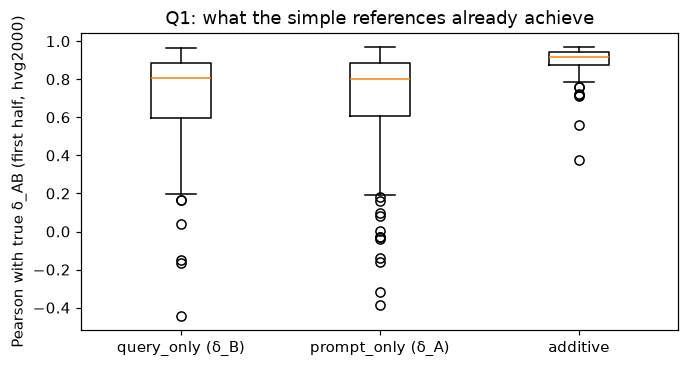

,query_only (δ_B),prompt_only (δ_A),additive
mean,0.713,0.675,0.896
25%,0.598,0.606,0.877
50%,0.806,0.800,0.918
75%,0.885,0.885,0.941


In [13]:
refs = {}
for d in doubles:
    a_, b_ = d.split("+")
    dA, dB = single_eff_all.loc[a_, PANEL_GENES], single_eff_all.loc[b_, PANEL_GENES]
    dAB = truth_all.loc[d, PANEL_GENES] - ctrl_all[PANEL_GENES]
    refs[d] = {"query_only (δ_B)": np.corrcoef(dAB, dB)[0, 1], "prompt_only (δ_A)": np.corrcoef(dAB, dA)[0, 1],
               "additive": np.corrcoef(dAB, dA + dB)[0, 1]}
refs = pd.DataFrame(refs).T
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot([refs[c] for c in refs], tick_labels=refs.columns)
ax.set(ylabel=f"Pearson with true δ_AB (first half, {PANEL})", title="Q1: what the simple references already achieve")
plt.show()
refs.describe().loc[["mean", "25%", "50%", "75%"]].round(3)

## Q2 — Which behaviour does STACK show?

**In short:** when STACK gets "A as the prompt, B as the query", it might:
- **replace** B with A, predicting A's effect;
- **preserve** B, ignoring A;
- **add** them, which is good;
- or even predict the **interaction**, which is best.

We measure which of these happens.

**Split — S-all**, both orders: 262 pair-orders.

**Models tested:** `stack_frozen` per order (later also `stack_finetuned`). References are the
measured truth's own (c_A, c_B) below.

**Metrics:** per pair-order, the same specific-epistasis weights as Part B, fitted to the prediction:
δ̂_AB ≈ β_P·δ_prompt + β_Q·δ_query (+ shared ε), on the HVG panel:
- (1, 0) = replacement;
- (0, 1) = preservation;
- (1, 1) = additive;
- residual Pearson corr(r̂, r) = interaction.

**Data view:** where the *truth* sits on this map. A good model's (β_P, β_Q) should land in the
same place as the truth's (c_A, c_B), not in a corner.

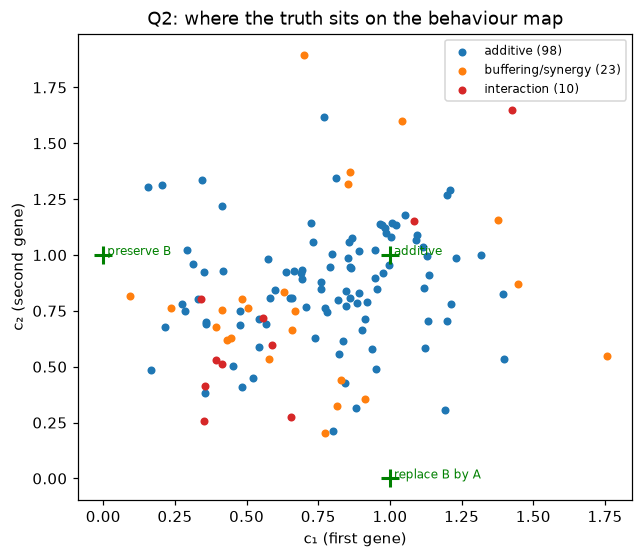

In [14]:
a = additivity
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for g, color in [("additive", "C0"), ("buffering/synergy", "C1"), ("interaction", "C3")]:
    sub = a[a["group"] == g]
    ax.scatter(sub["c1 (first gene)"], sub["c2 (second gene)"], s=18, c=color, label=f"{g} ({len(sub)})")
for (x, y, t) in [(1, 0, "replace B by A"), (0, 1, "preserve B"), (1, 1, "additive")]:
    ax.plot([x], [y], "g+", ms=12, mew=2); ax.annotate(" " + t, (x, y), color="green", fontsize=8)
ax.set(xlabel="c₁ (first gene)", ylabel="c₂ (second gene)", title="Q2: where the truth sits on the behaviour map")
ax.legend(fontsize=8); plt.show()

## Q3 — Does the order matter?

**In short:** the target (cells with A and B) is the same whichever gene is shown as the prompt.
A model that really composes should give the same answer both ways. We compare A→B with B→A, and
test whether averaging the two ("both orders") helps.

**Split — S-all**, every pair in both orders, compared pair by pair.

**Models tested:** `stack_frozen` A→B, `stack_frozen` B→A, `stack_sym` (mean of the two); later the
same for `stack_finetuned` (± consistency).

**Metrics:**
- paired difference in wMSE (A→B minus B→A) per pair, with a bootstrap CI and a sign test;
- the correlation between the two orders' predictions;
- wMSE of `stack_sym` vs the better single order.

**Data view:** pairs whose two singles differ a lot in strength are where order effects are most
likely. For example, if STACK copies its query, the query's strength decides the answer.

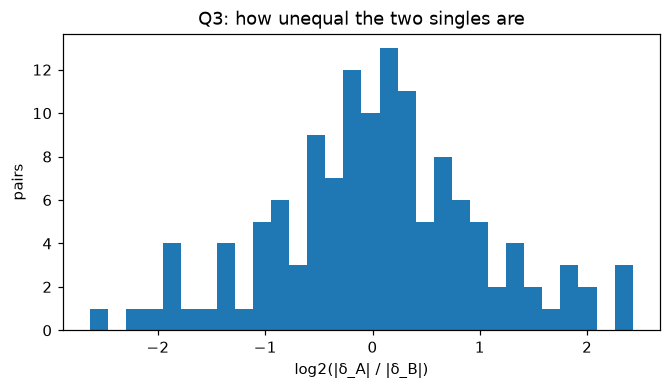

,|δ_A|,|δ_B|,log2 ratio
ZC3HAV1+CEBPA,1.37,8.49,-2.63
KLF1+BAK1,3.14,0.58,2.42
CEBPE+RUNX1T1,5.04,0.97,2.38
MAP2K6+IKZF3,1.22,5.95,-2.29
MAPK1+TGFBR2,3.85,0.80,2.26
TGFBR2+PRTG,0.80,3.27,-2.03
TMSB4X+BAK1,2.30,0.58,1.97
KLF1+TGFBR2,3.14,0.80,1.97
MAP2K3+IKZF3,1.57,5.95,-1.92
MAP2K6+SPI1,1.22,4.55,-1.90


In [15]:
asym = pd.DataFrame({
    "|δ_A|": [np.linalg.norm(effects.loc[d.split("+")[0]]) for d in doubles],
    "|δ_B|": [np.linalg.norm(effects.loc[d.split("+")[1]]) for d in doubles],
}, index=doubles)
asym["log2 ratio"] = np.log2(asym["|δ_A|"] / asym["|δ_B|"])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(asym["log2 ratio"], bins=30)
ax.set(xlabel="log2(|δ_A| / |δ_B|)", ylabel="pairs", title="Q3: how unequal the two singles are")
plt.show()
asym.reindex(asym["log2 ratio"].abs().sort_values(ascending=False).index).head(10).round(2)

## Q4 — Does fine-tuning help on new combinations, and on new genes?

**In short:** we train STACK on some pairs and test it on pairs it has never seen. Predicting a
new pair is easier when both genes appeared in other training pairs, and harder when a gene is
completely new to the pair data. So we hide some genes on purpose and report results for:
- **seen 2/2:** both genes appear in training pairs;
- **unseen 1/2:** one gene is new;
- **unseen 2/2:** both genes are new.

The single-gene measurements are always available.

**Split — S-gene**, 5 random seeds:
- Hold out ~15% of the 73 genes (set G). Every pair containing a gene in G is a test pair.
- Also test a random 15% of the remaining pairs ("seen 2/2").
- Train on the rest. Validation is built the same way inside the training pairs.

**Models tested:** `stack_finetuned` vs `stack_frozen`. The supervised baselines get exactly the same
training pairs: `ridge`, `knn`, `pca_linear`, TabPFN and `weighted`. Plus `additive` and the
controls and duplicates.

**Metrics:** wMSE (primary), Pearson Δ, DE AUPRC and direction agreement, per category. Median over
the 5 seeds, with paired bootstrap CIs.

**Data view:** a preview of what S-gene draws look like (computed here in memory, not saved). We
check that every category has enough pairs.

In [16]:
GENES = sorted(degree.index)

def s_gene_draw(seed, frac_genes=0.15, frac_seen=0.15, min_per_category=5, min_train_frac=0.6, tries=1000):
    rng = np.random.default_rng(seed)
    for attempt in range(tries):
        G = set(rng.choice(GENES, size=round(frac_genes * len(GENES)), replace=False))
        n_new = {d: sum(g in G for g in d.split("+")) for d in doubles}
        rest = [d for d in doubles if n_new[d] == 0]
        seen_test = set(rng.choice(rest, size=round(frac_seen * len(rest)), replace=False))
        cat = {d: ("unseen 2/2" if n_new[d] == 2 else "unseen 1/2" if n_new[d] == 1
                   else "seen 2/2 (test)" if d in seen_test else "train") for d in doubles}
        c = Counter(cat.values())
        if (min(c["unseen 2/2"], c["unseen 1/2"], c["seen 2/2 (test)"]) >= min_per_category
                and c["train"] >= min_train_frac * len(doubles)):
            return pd.Series(cat), sorted(G), attempt
    return None, None, tries

preview = {}
for seed in range(5):
    cat, G, attempt = s_gene_draw(seed)
    preview[seed] = (Counter(cat.tolist()) if cat is not None else {}) | {"resamples": attempt, "held-out genes": len(G or [])}
display(pd.DataFrame(preview).T.fillna(0).astype(int))
cat0, G0, _ = s_gene_draw(0)
print("seed 0 held-out genes:", G0)
print("unseen 2/2 pairs (seed 0):", sorted(cat0[cat0 == "unseen 2/2"].index))

,unseen 1/2,train,seen 2/2 (test),unseen 2/2,resamples,held-out genes
0,26,85,15,5,60,11
1,30,81,14,6,9,11
2,25,86,15,5,10,11
3,30,82,14,5,17,11
4,22,88,16,5,17,11


seed 0 held-out genes: [np.str_('CBFA2T3'), np.str_('CDKN1C'), np.str_('ELMSAN1'), np.str_('FEV'), np.str_('FOXL2'), np.str_('HOXB9'), np.str_('MAP2K6'), np.str_('PLK4'), np.str_('POU3F2'), np.str_('RUNX1T1'), np.str_('TBX3')]
unseen 2/2 pairs (seed 0): ['FEV+CBFA2T3', 'FOXL2+HOXB9', 'MAP2K6+ELMSAN1', 'POU3F2+CBFA2T3', 'POU3F2+FOXL2']


## Q5 — Does making both orders agree help?

**In short:** we fine-tune STACK with an extra rule: "your A→B and B→A answers should match".
Does that make predictions on new pairs better, or just more consistent?

**Split — S-gene** (the same 5 seeds as Q4, so the two fine-tuned versions are compared on
identical pairs). Optional **S-order** check: train only on A→B, then test B→A, to see if
fine-tuning learns an order-specific shortcut.

**Models tested:** `stack_finetuned` vs `stack_finetuned + consistency` (and each one's `sym` average).

**Metrics:**
- wMSE and Pearson Δ per category;
- the order gap |wMSE(A→B) − wMSE(B→A)|;
- for S-order, B→A minus A→B on the same pairs.

**Data view:** how many training pairs and pair-orders each S-gene seed gives fine-tuning to learn from.

In [17]:
train_sizes = {}
for seed in range(5):
    cat, _, _ = s_gene_draw(seed)
    n = int((cat == "train").sum())
    train_sizes[seed] = {"training pairs": n, "training pair-orders (both orders)": 2 * n,
                         "S-order: one order only": n}
pd.DataFrame(train_sizes).T

,training pairs,training pair-orders (both orders),S-order: one order only
0,85,170,85
1,81,162,81
2,86,172,86
3,82,164,82
4,88,176,88


## Q6 — Which pairs are additive, and does any model capture the rest?

**In short:** we check each real pair *before* testing any model, by asking how well the simple
guess "A's effect + B's effect" matches the measured double. Each pair gets a **ruler**:

- **0** = as good as repeating the experiment (the "redo": the second half of the pair's cells,
  graded against the first half);
- **1** = as bad as guessing "nothing changes" (normal control cells).

The plain sum lands somewhere on that ruler. We also try a **stretched/shrunk sum**, c₁·A + c₂·B,
where each pair gets its own two weights:
- **near 0 on the plain sum** → the pair is **additive**;
- **far on the plain sum but near 0 on the stretched sum** → the effects add but come out weaker
  (**buffering**, c's < 1) or stronger (**synergy**, c's > 1);
- **far on both** → a **real interaction**: something new happens that no mix of A and B explains.

Later, every model (STACK, additive, weighted, ridge) is reported separately for these groups.
**Agreed cutoff:** the 25% of pairs furthest from 0 on the plain sum are non-additive. The same
number splits them into buffering/synergy and interaction.

**Split:** these scores depend only on the data, so they are computed once for all 131 pairs and
reused inside every split.

**Metrics later:** wMSE on each group; residual Pearson corr(r̂, r), with r = δ_AB − (δ_A + δ_B).

**Technical:** follows the reference methods ("metric calibration", "specific epistasis model"):
- **score** = (wMSE(guess) − wMSE(redo)) / (wMSE(control) − wMSE(redo)), clipped at 0. Pairs where
  the redo is not better than control are dropped, as the paper does.
- **wMSE** is exactly the shared scoring's: weights = min-max-scaled squared t-scores from the DE
  test of the pair's **first half** vs all other perturbed first-half cells.
- **Truth** = the first-half mean; **redo** = the second-half mean; singles use all their cells.
- **Stretched sum** = control + c₁δ_A + c₂δ_B + ε, one joint least-squares fit over all 131 doubles
  (per-pair c's, one shared gene offset ε). It uses each pair's own truth, so it is a descriptive
  **oracle**, not a predictor.
- Computed on the HVG panel (main) and on all STACK genes.

In [18]:
# Computed in Part B (same truth halves, wMSE weights and fits as the scoring).
r = ruler[PANEL]
r[["score: plain sum", "score: stretched sum"]].describe().round(3)

,score: plain sum,score: stretched sum
count,131.000,131.000
mean,0.104,0.053
std,0.138,0.073
min,0.000,0.000
25%,0.029,0.007
50%,0.064,0.026
75%,0.117,0.061
max,0.865,0.417


**Plot 1: where the plain sum lands on the ruler, for all 131 pairs.** A pile near 0 = additive
pairs. A long tail = pairs the sum gets wrong. Look for a natural gap that could serve as the cutoff.

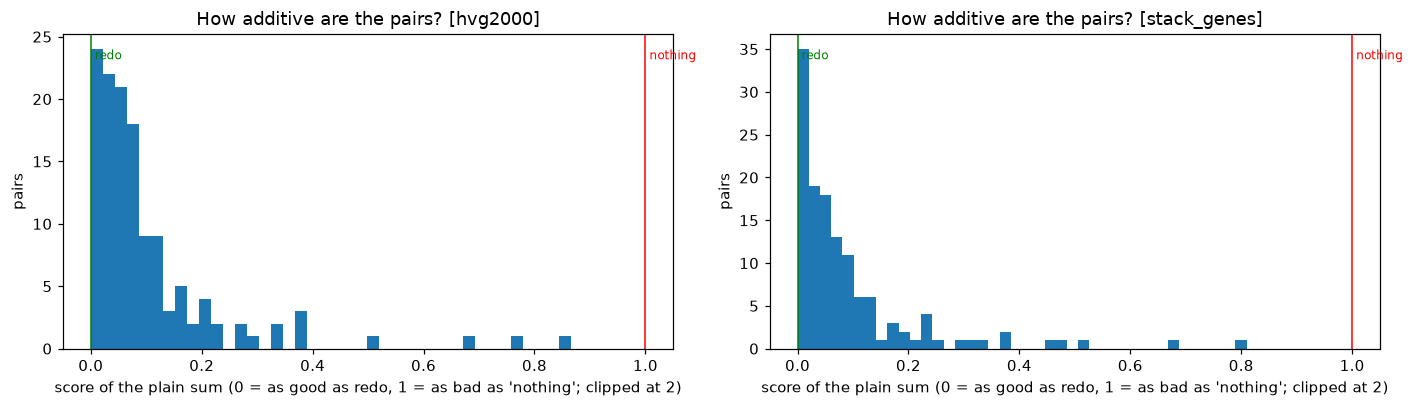

count    131.000
mean       0.104
std        0.138
min        0.000
10%        0.002
25%        0.029
50%        0.064
75%        0.117
90%        0.233
max        0.865


In [19]:
fig, axes = plt.subplots(1, len(ruler), figsize=(6.5 * len(ruler), 3.8), squeeze=False)
for ax, (name, r) in zip(axes[0], ruler.items()):
    s = r["score: plain sum"].dropna()
    ax.hist(s.clip(upper=2), bins=40)
    ax.axvline(0, c="green", lw=1); ax.axvline(1, c="red", lw=1)
    ax.text(0, ax.get_ylim()[1] * 0.92, " redo", color="green", fontsize=8)
    ax.text(1, ax.get_ylim()[1] * 0.92, " nothing", color="red", fontsize=8)
    ax.set(xlabel="score of the plain sum (0 = as good as redo, 1 = as bad as 'nothing'; clipped at 2)",
           ylabel="pairs", title=f"How additive are the pairs? [{name}]")
plt.tight_layout(); plt.show()
r = ruler[PANEL]
print(r["score: plain sum"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3).to_string())

**The agreed groups (cut = top 25% of the plain-sum score):**
- **additive:** plain sum below the cut;
- **buffering/synergy:** plain sum above the cut, stretched sum below it;
- **interaction:** both above it.

They are saved by `scripts/make_additivity_groups.py` to `splits/compositional/additivity_groups.csv`
and used in every split and results table.

In [20]:
display(r["group"].value_counts().to_frame("pairs"))
r[r["group"] != "additive"].sort_values(["group", "score: plain sum"], ascending=[True, False])[
    ["group", "score: plain sum", "score: stretched sum", "c1 (first gene)", "c2 (second gene)", "cells", "Study 4 list"]].round(3)

,pairs
group,
additive,98
buffering/synergy,23
interaction,10


,group,score: plain sum,score: stretched sum,c1 (first gene),c2 (second gene),cells,Study 4 list
MAP2K3+MAP2K6,buffering/synergy,0.768,0.000,0.393,0.678,571,False
ZC3HAV1+CEBPE,buffering/synergy,0.690,0.095,0.913,0.354,410,False
CEBPE+CEBPA,buffering/synergy,0.512,0.012,0.432,0.618,180,False
IGDCC3+PRTG,buffering/synergy,0.387,0.000,0.816,0.324,140,False
CEBPE+RUNX1T1,buffering/synergy,0.325,0.075,0.485,0.805,1219,False
CEBPB+CEBPA,buffering/synergy,0.301,0.000,0.094,0.815,64,False
PTPN12+UBASH3A,buffering/synergy,0.266,0.047,1.757,0.550,311,False
DUSP9+SNAI1,buffering/synergy,0.237,0.094,0.700,1.895,183,True
CEBPE+CEBPB,buffering/synergy,0.233,0.026,0.830,0.442,114,False
CEBPE+KLF1,buffering/synergy,0.206,0.093,0.236,0.761,468,False


**Plot 2: plain sum vs stretched sum.** Bottom-left = additive. Right side but low = buffering or
synergy (a stretched/shrunk sum fixes it). Top-right = a real interaction. Labels show the pairs
furthest from additive; red rings are Study 4's 9-pair list.

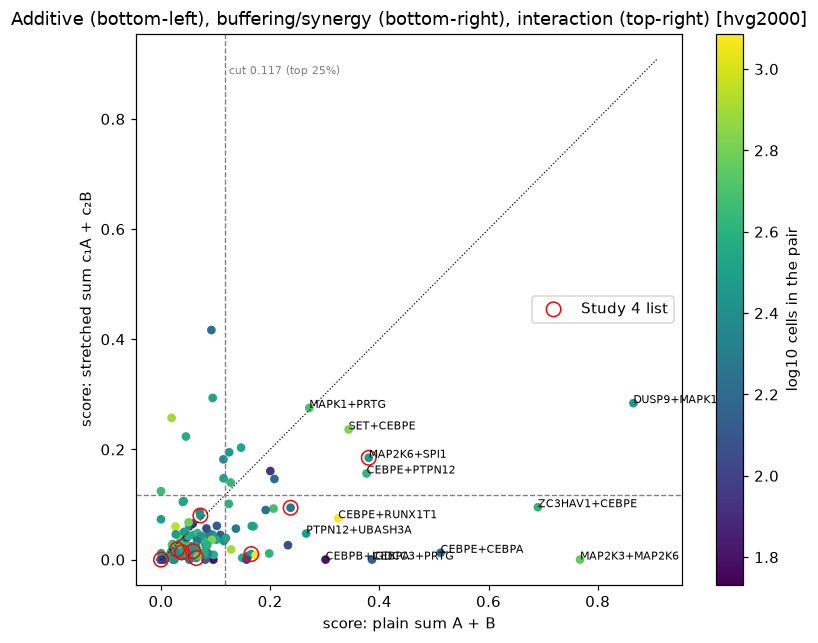

,score: plain sum,score: stretched sum,c1 (first gene),c2 (second gene),|AB| top-100 DE,|A+B| top-100 DE,"pearson(AB, A+B) panel","pearson(AB, A+B) top-100 DE",wMSE plain sum,wMSE redo,wMSE nothing,cells,Study 4 list,group
DUSP9+MAPK1,0.865,0.284,0.353,0.259,1.479,2.761,0.801,0.837,0.019,0.002,0.022,290,False,interaction
MAP2K3+MAP2K6,0.768,0.000,0.393,0.678,1.218,2.177,0.910,0.961,0.010,0.002,0.013,571,False,buffering/synergy
ZC3HAV1+CEBPE,0.690,0.095,0.913,0.354,2.050,3.816,0.874,0.933,0.054,0.002,0.078,410,False,buffering/synergy
CEBPE+CEBPA,0.512,0.012,0.432,0.618,6.555,11.153,0.971,0.981,0.204,0.007,0.392,180,False,buffering/synergy
IGDCC3+PRTG,0.387,0.000,0.816,0.324,3.032,4.877,0.932,0.958,0.059,0.008,0.140,140,False,buffering/synergy
MAP2K6+SPI1,0.381,0.185,0.356,0.416,1.786,2.600,0.838,0.905,0.021,0.002,0.052,302,True,interaction
CEBPE+PTPN12,0.377,0.156,0.394,0.530,2.003,3.557,0.885,0.915,0.054,0.001,0.140,415,False,interaction
SET+CEBPE,0.344,0.236,0.656,0.277,2.908,4.616,0.843,0.905,0.071,0.001,0.203,658,False,interaction
CEBPE+RUNX1T1,0.325,0.075,0.485,0.805,2.627,4.414,0.963,0.979,0.049,0.001,0.150,1219,False,buffering/synergy
CEBPB+CEBPA,0.301,0.000,0.094,0.815,6.508,9.853,0.931,0.976,0.109,0.016,0.323,64,False,buffering/synergy


In [21]:
r = ruler[PANEL]
fig, ax = plt.subplots(figsize=(8, 6.5))
sc_ = ax.scatter(r["score: plain sum"].clip(upper=2), r["score: stretched sum"].clip(upper=2),
                 c=np.log10(r["cells"].astype(float)), cmap="viridis", s=22)
st4 = r[r["Study 4 list"]]
ax.scatter(st4["score: plain sum"].clip(upper=2), st4["score: stretched sum"].clip(upper=2), s=90,
           facecolors="none", edgecolors="red", label="Study 4 list")
for d in r["score: plain sum"].nlargest(12).index:
    ax.annotate(d, (min(r.loc[d, "score: plain sum"], 2), min(r.loc[d, "score: stretched sum"], 2)), fontsize=7)
lim = min(2, np.nanmax(r[["score: plain sum", "score: stretched sum"]].to_numpy()) * 1.05)
ax.plot([0, lim], [0, lim], "k:", lw=0.8)
ax.axvline(CUT, c="grey", ls="--", lw=0.9); ax.axhline(CUT, c="grey", ls="--", lw=0.9)
ax.text(CUT, lim * 0.97, f" cut {CUT:.3f} (top 25%)", fontsize=7, color="grey")
fig.colorbar(sc_, ax=ax, label="log10 cells in the pair")
ax.set(xlabel="score: plain sum A + B", ylabel="score: stretched sum c₁A + c₂B",
       title=f"Additive (bottom-left), buffering/synergy (bottom-right), interaction (top-right) [{PANEL}]")
ax.legend(); plt.show()
r.sort_values("score: plain sum", ascending=False).head(30).round(3)

In [22]:
# Check: on the 26 shared test pairs, the plain-sum score must equal the one computed from the
# scored pipeline (results/compositional/s_shared/scores.csv: additive, technical_duplicate,
# control_baseline wMSE, halves mode, STACK gene panel).
scores_path = ROOT / "results/compositional/s_shared/scores.csv"
if scores_path.exists() and "stack_genes" in ruler:
    sc_long = pd.read_csv(scores_path).query("truth == 'halves' and panel == 'stack_genes' and metric == 'wmse'")
    w = sc_long.pivot(index="perturbation", columns="model", values="value")
    from_pipeline = pd.Series(calibrated(w["additive"], w["technical_duplicate"], w["control_baseline"]), index=w.index)
    here = ruler["stack_genes"].loc[w.index, "score: plain sum"]
    print("max |difference| vs scored pipeline:", float((from_pipeline - here).abs().max()))
else:
    print("scored pipeline output not found; run scripts/build_contexts.py --split s_shared")

max |difference| vs scored pipeline: 6.938893903907228e-17


## Reference — the team's split (S-shared)

**In short:** the team's baseline table and Study 4 use one random split: 26 held-out pairs, with
all 105 singles and the other 105 pairs for training. We keep it unchanged and also report our
models on it, so everyone's numbers can be put side by side.

**Split — S-shared:** `splits/norman2019_conditions.csv` (seed 0); validation =
`splits/norman2019_val_conditions.csv`.

**Models tested:** every Exp. 2 arm, next to the team's baselines.

**Metrics:** all shared metrics, read from `EvalContext.score` exactly as in the team's results.

**Data view:** the 26 held-out pairs, how many training pairs share a gene with each, and where
each sits on the additivity ruler (Q6).

In [23]:
split = pd.read_csv(ROOT / "splits/norman2019_conditions.csv")
test = split.loc[split["split"].eq("test"), "condition"].tolist()
train_doubles = split.query("split == 'train' and kind == 'combination'")["condition"].tolist()
seen = {g for d in train_doubles for g in d.split("+")}
shared = pd.DataFrame({
    t: {"cells": counts[t], "neighbours": sum(bool(set(d.split("+")) & set(t.split("+"))) for d in train_doubles),
        "genes seen in training pairs": sum(g in seen for g in t.split("+")),
        "score: plain sum": round(ruler[PANEL].loc[t, "score: plain sum"], 3),
        "score: stretched sum": round(ruler[PANEL].loc[t, "score: stretched sum"], 3),
        "group": additivity.loc[t, "group"], "Study 4 list": t in STUDY4_NON_ADDITIVE}
    for t in test}).T
shared

,cells,neighbours,genes seen in training pairs,score: plain sum,score: stretched sum,group,Study 4 list
AHR+FEV,276,3,1,0.029,0.019,additive,True
AHR+KLF1,481,7,1,0.059,0.015,additive,True
BPGM+SAMD1,301,4,2,0.064,0.003,additive,True
CBL+PTPN12,335,14,2,0.039,0.013,additive,True
CEBPB+PTPN12,331,15,2,0.115,0.148,additive,False
DUSP9+ETS2,787,11,2,0.128,0.018,buffering/synergy,False
DUSP9+PRTG,297,7,2,0.165,0.01,buffering/synergy,True
DUSP9+SNAI1,183,7,2,0.237,0.094,buffering/synergy,True
FOXA1+FOXF1,272,5,2,0.115,0.034,additive,False
FOXA3+FOXF1,175,4,2,0.066,0.034,additive,False
